# Trabalho de Álgebra Linear — Entrega 2
## Transformações lineares aplicadas à comparação contextualizada de perfis em um agente acadêmico

**Integrantes:** Esther Oliveira Costa — RA24026817; Higor Luiz Fonseca dos Santos — RA24026818; João Victor de Faria Santana — RA24026811.  
**São Paulo – SP, 2026**

**Objetivo:** aplicar uma transformação linear aos vetores da Entrega 1 para adaptar a distância entre perfis ao tipo de solicitação recebida pelo agente.

## 1. Contexto e problema identificado na Entrega 1

Na Entrega 1, cada estudante foi representado por cinco características normalizadas: **progresso acadêmico, nota, assiduidade, contatos e regularidade financeira**. Compararam-se dois alunos por distância euclidiana, produto escalar e ângulo.

**Limitação a melhorar:** a distância euclidiana original trata todas as cinco diferenças como igualmente importantes. Porém, uma solicitação acadêmica e uma solicitação financeira podem requerer prioridades diferentes.

**Proposta:** criar duas transformações lineares, uma para o contexto **acadêmico** e outra para o **financeiro**, e comparar as distâncias produzidas. Os pesos usados são **hipóteses ilustrativas**, não regras reais da instituição; precisariam ser validados antes de uso operacional.

## 2. Dados e representação matemática preservados

Utilizamos os mesmos valores numéricos da Entrega 1, sem inventar alunos ou consultar dados adicionais. Os arquivos-fonte citados originalmente (`Matriculas.xlsx`, `Historico.xlsx`, `Relacionamentos.xlsx` e `Financeiro.xlsx`) não são necessários para reproduzir este exemplo com dois perfis.

A ordem das componentes é:

$$v=[\mathrm{progresso},\ \mathrm{nota},\ \mathrm{assiduidade},\ \mathrm{contatos},\ \mathrm{regularidade}]$$

A matriz $M\in\mathbb{R}^{2\times5}$ terá uma linha por estudante e uma coluna por característica.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
caracteristicas = ["Progresso", "Nota", "Assiduidade", "Contatos", "Regularidade financeira"]
ids = ["12621", "17578"]
aluno_12621 = np.array([7/8, 62.4/100, 100/100, 15/143, 0.25], dtype=float)
aluno_17578 = np.array([8/8, 82.088947/100, 100/100, 0/143, 1.0], dtype=float)
M = np.vstack([aluno_12621, aluno_17578])
print("Matriz original M (alunos x características):\n", M)
print("Formato:", M.shape)
print("Distância euclidiana original:", round(np.linalg.norm(M[0] - M[1]), 6))

Matriz original M (alunos x características):
 [[0.875    0.624    1.       0.104895 0.25    ]
 [1.       0.820889 1.       0.       1.      ]]
Formato: (2, 5)
Distância euclidiana original: 0.792397


## 3. Conceito avançado: transformação linear

Uma transformação linear $T:\mathbb{R}^5\to\mathbb{R}^5$ pode ser representada por uma matriz $A$ tal que **$T(v)=Av$**. Para dar importância diferente às características, adotamos uma matriz diagonal:

$$A=\mathrm{diag}(\sqrt{w_1},\sqrt{w_2},\sqrt{w_3},\sqrt{w_4},\sqrt{w_5})$$

Os pesos $w_j$ são não negativos e somam 1. A raiz quadrada é importante: ao calcular a distância euclidiana **após** a transformação, obtemos exatamente a distância ponderada:

$$d_w(u,v)=\|Au-Av\|_2=\sqrt{\sum_{j=1}^{5}w_j(u_j-v_j)^2}.$$

A transformação é linear porque $T(lpha u+eta v)=lpha T(u)+eta T(v)$.

### Pesos exemplificativos por tipo de solicitação

| Característica | Contexto acadêmico | Contexto financeiro |
|---|---:|---:|
| Progresso | 0,30 | 0,10 |
| Nota | 0,30 | 0,10 |
| Assiduidade | 0,20 | 0,10 |
| Contatos | 0,10 | 0,10 |
| Regularidade financeira | 0,10 | 0,60 |

**Observação:** são cenários didáticos, não pesos aprendidos a partir de dados. A escolha de pesos pode ter implicações de privacidade, equidade e adequação ao propósito do atendimento.

In [2]:
pesos = {
    "Acadêmico": np.array([0.30, 0.30, 0.20, 0.10, 0.10]),
    "Financeiro": np.array([0.10, 0.10, 0.10, 0.10, 0.60]),
}
transformacoes = {}
for contexto, w in pesos.items():
    assert np.all(w >= 0) and np.isclose(w.sum(), 1)
    A = np.diag(np.sqrt(w))
    transformacoes[contexto] = A
    print(f"\nMatriz A — {contexto}:\n{A}")
    print("T(v12621) =", A @ aluno_12621)
    print("T(v17578) =", A @ aluno_17578)
    # Verificação numérica da propriedade de linearidade
    alpha, beta = 2.0, -0.5
    print("Linearidade verificada:", np.allclose(A @ (alpha*aluno_12621 + beta*aluno_17578),
                                          alpha*(A @ aluno_12621) + beta*(A @ aluno_17578)))


Matriz A — Acadêmico:
[[0.547723 0.       0.       0.       0.      ]
 [0.       0.547723 0.       0.       0.      ]
 [0.       0.       0.447214 0.       0.      ]
 [0.       0.       0.       0.316228 0.      ]
 [0.       0.       0.       0.       0.316228]]
T(v12621) = [0.479257 0.341779 0.447214 0.033171 0.079057]
T(v17578) = [0.547723 0.44962  0.447214 0.       0.316228]
Linearidade verificada: True

Matriz A — Financeiro:
[[0.316228 0.       0.       0.       0.      ]
 [0.       0.316228 0.       0.       0.      ]
 [0.       0.       0.316228 0.       0.      ]
 [0.       0.       0.       0.316228 0.      ]
 [0.       0.       0.       0.       0.774597]]
T(v12621) = [0.276699 0.197326 0.316228 0.033171 0.193649]
T(v17578) = [0.316228 0.259588 0.316228 0.       0.774597]
Linearidade verificada: True


## 4. Cálculos: distâncias e decomposição das diferenças

Compare a distância original (todas as componentes sem ponderação) com as duas distâncias transformadas. **As escalas não são iguais**: como os pesos somam 1, as distâncias transformadas são menores em magnitude do que a original. Para comparação mais direta, também mostramos uma referência de pesos iguais, $w_j=0{,}20$. Todas as distâncias transformadas usam a mesma escala de ponderação.

Para interpretar o resultado, calculamos também a parcela $w_j(u_j-v_j)^2$ de cada componente: quanto maior a parcela, maior a influência da característica na **distância quadrática**.

In [3]:
delta = aluno_12621 - aluno_17578
d_original = np.linalg.norm(delta)
d_igual = np.sqrt(np.sum(np.full(5, 0.2) * delta**2))
print(f"Distância original (Entrega 1): {d_original:.6f}")
print(f"Distância com pesos iguais somando 1: {d_igual:.6f} = original / sqrt(5)")

resultados = {}
for contexto, A in transformacoes.items():
    w = pesos[contexto]
    d_transformada = np.linalg.norm(A @ aluno_12621 - A @ aluno_17578)
    d_formula = np.sqrt(np.sum(w * delta**2))
    assert np.isclose(d_transformada, d_formula)
    parcelas = w * delta**2
    resultados[contexto] = {"distancia": d_transformada, "parcelas": parcelas}
    print(f"\n{contexto}: distância = {d_transformada:.6f}")
    for nome, parcela in zip(caracteristicas, parcelas):
        print(f"  {nome:<25}: {parcela:.6f} ({parcela/parcelas.sum()*100:.1f}% da distância ao quadrado)")

Distância original (Entrega 1): 0.792397
Distância com pesos iguais somando 1: 0.354371 = original / sqrt(5)

Acadêmico: distância = 0.271417
  Progresso                : 0.004687 (6.4% da distância ao quadrado)
  Nota                     : 0.011630 (15.8% da distância ao quadrado)
  Assiduidade              : 0.000000 (0.0% da distância ao quadrado)
  Contatos                 : 0.001100 (1.5% da distância ao quadrado)
  Regularidade financeira  : 0.056250 (76.4% da distância ao quadrado)

Financeiro: distância = 0.586549
  Progresso                : 0.001563 (0.5% da distância ao quadrado)
  Nota                     : 0.003877 (1.1% da distância ao quadrado)
  Assiduidade              : 0.000000 (0.0% da distância ao quadrado)
  Contatos                 : 0.001100 (0.3% da distância ao quadrado)
  Regularidade financeira  : 0.337500 (98.1% da distância ao quadrado)


## 5. Visualização dos resultados

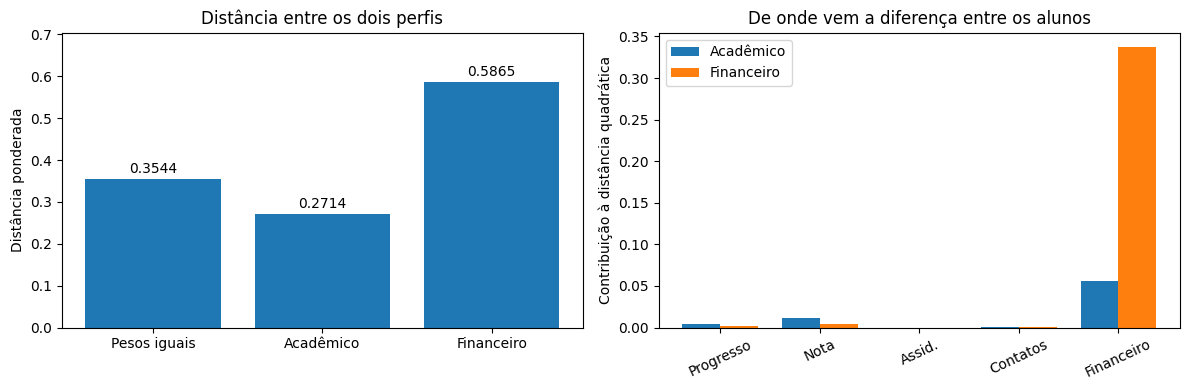

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
nomes = ["Pesos iguais", "Acadêmico", "Financeiro"]
valores = [d_igual, resultados["Acadêmico"]["distancia"], resultados["Financeiro"]["distancia"]]
axs[0].bar(nomes, valores)
axs[0].set_title("Distância entre os dois perfis")
axs[0].set_ylabel("Distância ponderada")
axs[0].set_ylim(0, max(valores)*1.2)
for i, v in enumerate(valores):
    axs[0].text(i, v + 0.015, f"{v:.4f}", ha="center")

x = np.arange(len(caracteristicas))
width = 0.38
axs[1].bar(x-width/2, resultados["Acadêmico"]["parcelas"], width, label="Acadêmico")
axs[1].bar(x+width/2, resultados["Financeiro"]["parcelas"], width, label="Financeiro")
axs[1].set_xticks(x, ["Progresso", "Nota", "Assid.", "Contatos", "Financeiro"], rotation=25)
axs[1].set_ylabel("Contribuição à distância quadrática")
axs[1].set_title("De onde vem a diferença entre os alunos")
axs[1].legend()
plt.tight_layout()
plt.show()

## 6. Interpretação: o que mudou no agente?

**Antes (Entrega 1):** o agente calculava uma única distância de aproximadamente **0,7924**, independentemente do assunto da solicitação.

**Depois (Entrega 2):** a mesma dupla de perfis apresenta distâncias diferentes conforme o contexto:

- Com pesos iguais que somam 1: **0,3544** (referência na mesma escala).
- No atendimento **acadêmico**: **0,2714**. A distância diminui em relação à referência de pesos iguais, pois há menor destaque para a regularidade financeira, a maior diferença observada entre os dois perfis.
- No atendimento **financeiro**: **0,5865**. A distância aumenta em relação à referência porque a diferença de regularidade financeira (0,25 versus 1,00) passa a concentrar mais peso.

A **assiduidade não contribui para a diferença**, porque ambos os alunos possuem o mesmo valor (1,00). O resultado mostra, concretamente, que uma transformação linear altera a geometria das comparações para destacar dimensões pertinentes à solicitação.

**Aplicação no fluxo do agente:** (1) identificar o assunto da solicitação; (2) selecionar pesos previamente aprovados; (3) transformar o vetor do estudante e vetores de casos históricos pela mesma matriz; (4) calcular distâncias transformadas; (5) recuperar casos potencialmente relevantes para análise, sem definir automaticamente o atendimento.

**Limitações:** com somente dois perfis não é possível comprovar melhora de precisão, fazer ranqueamentos significativos ou estabelecer limiares confiáveis. Os pesos são exemplos e precisariam de validação por especialistas e testes em conjunto maior, com cuidado para não empregar dados financeiros em situações sem necessidade legítima.

## 7. Conclusão

Esta entrega aplicou o conceito de **transformação linear por matriz diagonal** à representação vetorial construída na Entrega 1. Os cálculos em Python demonstraram que a distância entre os mesmos alunos pode mudar conforme os pesos atribuídos às características. Isso permite uma **análise contextualizada da similaridade matemática**, constituindo uma possibilidade de melhoria no mecanismo de recuperação de casos do agente acadêmico.

Não foi comprovada uma melhoria real de desempenho do agente: para isso seriam necessários dados históricos adicionais, critérios de avaliação, validação dos pesos e testes comparativos. A contribuição demonstrada aqui é **matemática e funcional**, atendendo à proposta de aplicar um conceito mais avançado de Álgebra Linear ao projeto.